# 01 Small nets and the arena

[![Open In Colab](https://colab.research.google.com/assets/colab/badge.svg)](https://colab.research.google.com/github/<owner>/dlnn-paper/blob/main/notebooks/01_small_nets_and_arena.ipynb)

**What this notebook does** (simulation only; the board is designed, not built, nothing is measured):

1. **Trains the small DLNN** (TDL-Net-B, width 8, d = 1, ternary taps) and the **arena baselines** (MLP-S, MLP-L, 1-D CNN, delay reservoir, cumulant features) with *lite* settings (minutes, not the full recipe), and compares them with the shipped models.
2. **Exports the arena data** (`arena_models.json`, `examples_arena.json`, `examples_gen_stats.json`, `energy_refs.json`, plus the small phase-1 net's `model_*.json` / `examples_*.json`) from the *shipped* models into `docs/artifacts/data/`, the exact files the article's widgets read.
3. **Checks the JavaScript forward passes** the widgets run (`docs/artifacts/assets/js/*.js`) against the Python reference, headless in `node` (skipped if `node` is absent).

The shipped models were trained with the full recipe (60 epochs, 3 restarts); the lite models here use fewer epochs and one seed, so their accuracy is expected to be a few points lower. They are exported to `docs/artifacts/data/lite/` (a set in which the retrained models replace their shipped copies; the feature MLPs and the board-aware DLNN-B stay shipped) and never replace the article's files.

In [1]:
# Colab only: install the system tools, clone the repo, install the pinned Python requirements. Skipped everywhere else.
import sys
if 'google.colab' in sys.modules:
    import os, subprocess
    REPO_URL = "https://github.com/<owner>/dlnn-paper"      # TODO: replace with the real URL once the repo is public
    subprocess.run("apt-get -qq install -y ngspice iverilog", shell=True, check=True)
    if not os.path.isdir("/content/dlnn-paper"):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "/content/dlnn-paper"], check=True)
    os.chdir("/content/dlnn-paper")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

In [2]:
import os, sys, time, json
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists() and (p / "dlnn").is_dir())
os.chdir(ROOT); sys.path.insert(0, str(ROOT))          # run from the repo root so relative paths in the library resolve
import numpy as np
from dlnn import paper
from dlnn.paper import DATA, EXPECTED, WORK
T0 = time.time()
ENV = paper.banner("01 Small nets and the arena")

01 Small nets and the arena
  python: 3.12.3
  numpy: 2.5.4
  platform: Linux-6.18.44-fc-v233-x86_64-with-glibc2.39
  ngspice: ngspice-42 : Circuit level simulation program
  iverilog: Icarus Verilog version 12.0 (stable) ()
  node: v22.23.4
  colab: False
  Simulation of a design that is not built. Nothing here is a measurement.


## 1. The task and the data

Eight synthetic modulation classes (OOK, BPSK, QPSK, 8PSK, 16QAM, 2FSK, 4FSK, GMSK), 128 complex samples, SNR 0 to 20 dB. The generator is deterministic; the dataset hash is checked against the one the shipped models were trained on.

In [3]:
from dlnn.data import modrec
from dlnn.model.npz import load_model
from dlnn.tiers import virtual
ds = modrec.dataset()
ref_report = paper.read_json("models/arena/arena_report.json")
print("classes", ds["classes"])
print("train", ds["x_train"].shape, "test", ds["x_test"].shape)
print("dataset sha256", ds["sha256"][:16], "| arena report", ref_report["dataset_sha256"][:16])
assert ds["sha256"] == ref_report["dataset_sha256"], "dataset differs from the one the shipped models were trained on"

def acc_V(model_path):
    """Accuracy of a dlnn-model/1 file on the 4000-example test set with the numpy ideal-math tier (V)."""
    m = load_model(model_path)
    return float((virtual.forward(m, ds["x_test"])["out"].argmax(1) == ds["y_test"]).mean())

classes ['OOK', 'BPSK', 'QPSK', '8PSK', '16QAM', '2FSK', '4FSK', 'GMSK']
train (16000, 2, 128) test (4000, 2, 128)
dataset sha256 e1b8e74480bdb325 | arena report e1b8e74480bdb325


## 2. Train the small DLNN, lite

The shipped recipe (`models/tdlnet_b_w8_report.json`): Adam, lr 0.03, cosine schedule, batch 256, **60 epochs, 3 restarts**, ternarisation ramped in over the first half. Lite: **20 epochs, 1 restart**. Two variants: a ternary readout (the all-analogue net) and a float digital readout (what the Nucleo would run, `DLNN-F`).

In [4]:
import contextlib, io
from dlnn.model import train
LITE = WORK / "lite" / "models"; LITE.mkdir(parents=True, exist_ok=True)
# start from a copy of the shipped models; whatever is retrained below overwrites its copy (the others, e.g. the feature MLPs and the
# board-aware DLNN-B, which needs the M1a line-FIR search, stay shipped and are listed as such)
import shutil
for f in [*Path("models").glob("tdlnet_b_w8*_ternary.npz"), *Path("models").glob("*.json")]:
    shutil.copyfile(f, LITE / f.name)
shutil.copytree("models/arena", LITE / "arena", dirs_exist_ok=True)
EPOCHS = int(os.environ.get("DLNN_LITE_EPOCHS", 20))
timing = {}
for name, extra in (("tdlnet_b_w8", []), ("tdlnet_b_w8_fro", ["--float-readout"])):
    t = time.time()
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        train.main(["--name", name, "--width", "8", "--depth", "3", "--dilations", "1,1,1", "--epochs", str(EPOCHS),
                    "--restarts", "1", "--ternary-only", "--out", str(LITE)] + extra)
    timing[name] = time.time() - t
    print(buf.getvalue().strip().splitlines()[-2])
    print(f"  {name}: {timing[name]:.0f} s")

ternary: acc 0.7835  acc>=10dB 0.8142  per-SNR {'0': 0.66875, '5': 0.80625, '10': 0.81125, '15': 0.8175, '20': 0.81375}  (15.9s)
  tdlnet_b_w8: 29 s


ternary: acc 0.8107  acc>=10dB 0.8546  per-SNR {'0': 0.67375, '5': 0.81625, '10': 0.865, '15': 0.8525, '20': 0.84625}  (11.3s)
  tdlnet_b_w8_fro: 12 s


In [5]:
rows = []
shipped = {"tdlnet_b_w8": paper.read_json("models/tdlnet_b_w8_report.json")["ternary"]["acc"],
           "tdlnet_b_w8_fro": ref_report["models"]["tdlnet_b_w8_fro"]["acc"]}
lite_acc = {}
for name in shipped:
    # shipped file re-evaluated here must reproduce its report exactly; the lite file only has to be in the right region
    s = acc_V(f"models/{name}_ternary.npz")
    l = acc_V(LITE / f"{name}_ternary.npz")
    lite_acc[name] = l
    paper.check(rows, f"{name}: shipped model, V accuracy vs report", s, shipped[name], 0.0005)
    paper.check(rows, f"{name}: lite ({EPOCHS} epochs, 1 seed) vs shipped", l, shipped[name], 0.10, note="lite recipe: expected a few points below")
    assert l > 0.55, "lite training did not learn"
df = paper.show_rows(rows)

                                               check     got  reference    tol unit result                                     note
    tdlnet_b_w8: shipped model, V accuracy vs report  0.8055     0.8055 0.0005        PASS                                         
    tdlnet_b_w8: lite (20 epochs, 1 seed) vs shipped  0.7835     0.8055    0.1        PASS lite recipe: expected a few points below
tdlnet_b_w8_fro: shipped model, V accuracy vs report 0.85125    0.85125 0.0005        PASS                                         
tdlnet_b_w8_fro: lite (20 epochs, 1 seed) vs shipped 0.81075    0.85125    0.1        PASS lite recipe: expected a few points below


## 3. Arena baselines, lite

Same data, same 4000 test examples. Lite settings: 8 epochs for the torch models, the reservoir and cumulant baselines unchanged (they are cheap). The shipped MLP and CNN numbers in the article come from larger searches (`models/arena/arena_report.json`).

In [6]:
from dlnn.model import arena
ARENA = LITE / "arena"; ARENA.mkdir(exist_ok=True)
t = time.time()
buf = io.StringIO()
with contextlib.redirect_stdout(buf):
    arena.main(["--only", "mlp_s,mlp_l,cnn,reservoir,cumulant,tdlnet_b_w8,tdlnet_b_w8_fro", "--out", str(ARENA),
                "--dlnn", str(LITE / "tdlnet_b_w8_ternary.npz"), "--epochs", "8"])
timing["arena"] = time.time() - t
print("\n".join(l for l in buf.getvalue().splitlines() if l[:12].strip() in ("cumulant","mlp_s","mlp_l","cnn","reservoir","tdlnet_b_w8","tdlnet_b_w8_fro")))
print(f"arena lite: {timing['arena']:.0f} s")
lite_rep = paper.read_json(ARENA / "arena_report.json")

cumulant     params    208 mults    27384 adds    26394 nonlin   1172 acc 0.8745 >=10dB 0.9583
mlp_s        params   1068 mults     1056 adds     1068 nonlin      4 acc 0.2670 >=10dB 0.2712
mlp_l        params   8488 mults     8448 adds     8488 nonlin     32 acc 0.5335 >=10dB 0.5521
cnn          params   1248 mults   147528 adds   151616 nonlin   3072 acc 0.8055 >=10dB 0.8404
reservoir    params   1544 mults    26496 adds  1341064 nonlin  12288 acc 0.7183 >=10dB 0.7438
tdlnet_b_w8  params   1275 mults     3144 adds    94784 nonlin   3072 acc 0.7835 >=10dB 0.8142
arena lite: 129 s


                                    check     got  reference  tol unit result                                    note
    tdlnet_b_w8: lite vs shipped accuracy  0.7835     0.8055 0.15        PASS     ops adds lite 94784 / shipped 93376
tdlnet_b_w8_fro: lite vs shipped accuracy 0.81075    0.85125 0.15        PASS     ops adds lite 89536 / shipped 88000
          mlp_s: lite vs shipped accuracy   0.267      0.261 0.15        PASS       ops adds lite 1068 / shipped 1068
          mlp_l: lite vs shipped accuracy  0.5335    0.54225 0.15        PASS      ops adds lite 8488 / shipped 10078
            cnn: lite vs shipped accuracy  0.8055    0.90925 0.15        PASS   ops adds lite 151616 / shipped 151616
      reservoir: lite vs shipped accuracy 0.71825    0.71825 0.15        PASS ops adds lite 1341064 / shipped 1341064
       cumulant: lite vs shipped accuracy  0.8745     0.8745 0.15        PASS     ops adds lite 26394 / shipped 26394


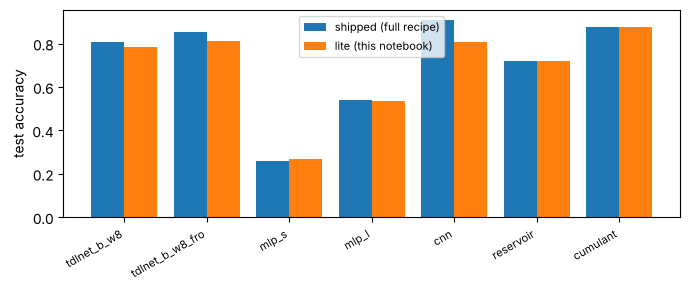

In [7]:
rows = []
for k in ("tdlnet_b_w8", "tdlnet_b_w8_fro", "mlp_s", "mlp_l", "cnn", "reservoir", "cumulant"):
    a_l, a_s = lite_rep["models"][k]["acc"], ref_report["models"][k]["acc"]
    ok = paper.check(rows, f"{k}: lite vs shipped accuracy", a_l, a_s, 0.15, note=f"ops adds lite {lite_rep['models'][k]['ops']['adds']} / shipped {ref_report['models'][k]['ops']['adds']}")
paper.show_rows(rows);
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 3))
ks = ["tdlnet_b_w8", "tdlnet_b_w8_fro", "mlp_s", "mlp_l", "cnn", "reservoir", "cumulant"]
x = np.arange(len(ks))
ax.bar(x - 0.2, [ref_report["models"][k]["acc"] for k in ks], 0.4, label="shipped (full recipe)")
ax.bar(x + 0.2, [lite_rep["models"][k]["acc"] for k in ks], 0.4, label="lite (this notebook)")
ax.set_xticks(x, ks, rotation=30, ha="right", fontsize=8); ax.set_ylabel("test accuracy"); ax.legend(fontsize=8); fig.tight_layout()

## 4. Export the data the article reads

From the **shipped** models (not the lite ones) into `docs/artifacts/data/`. The export is deterministic, so the files are compared byte for byte with the reference snapshot in `expected/data/`. Lite exports go to `docs/artifacts/data/lite/`.

In [8]:
from dlnn.viz import export_web
t = time.time()
p1 = export_web.export_modrec("models/tdlnet_modrec_ternary.npz", DATA, n=40)         # the phase-1 width-8 net used by the intro widget
p2 = export_web.export_arena("models", DATA, n=40)                                      # arena_models, examples_arena, examples_gen_stats, energy_refs
print("export", f"{time.time() - t:.1f} s")
rows = []
for k, p in {**p1, **p2}.items():
    ref = EXPECTED / "data" / Path(p).name
    same = ref.exists() and paper.sha256_file(p) == paper.sha256_file(ref)
    rows.append({"file": f"docs/artifacts/data/{Path(p).name}", "bytes": Path(p).stat().st_size, "sha256_16": paper.sha256_file(p)[:16],
                 "identical to reference snapshot": same})
import pandas as pd; print(pd.DataFrame(rows).to_string(index=False))

export 0.9 s
                                                file  bytes        sha256_16  identical to reference snapshot
docs/artifacts/data/model_tdlnet_modrec_ternary.json   3082 1527bd8817cad238                             True
             docs/artifacts/data/examples_arena.json  70524 52171ce2ee8491b3                             True
               docs/artifacts/data/arena_models.json 123570 cbe39bbd8bda013a                             True
         docs/artifacts/data/examples_gen_stats.json   8481 b50c6624d962b680                             True
                docs/artifacts/data/energy_refs.json   4114 6111a1578e321646                             True


In [9]:
t = time.time()
LITE_OUT = DATA / "lite"
export_web.export_arena(LITE, LITE_OUT, n=40) if (LITE / "arena" / "arena_report.json").exists() else None
print("lite export", f"{time.time() - t:.1f} s", sorted(p.name for p in LITE_OUT.glob("*.json")))

lite export 0.5 s ['arena_models.json', 'energy_refs.json', 'examples_arena.json', 'examples_gen_stats.json']


## 5. JavaScript forward pass vs Python

The widgets run `docs/artifacts/assets/js/tdlnet.js` and `arena.js` in the browser. Here the same code runs headless in `node` on the exported JSON and is compared with the numpy reference logits (tolerance 1e-5, top-1 must agree on every example). The JS signal generator is also checked statistically against the Python generator (`examples_gen_stats.json`).

In [10]:
import subprocess, shutil
NODE = shutil.which("node")
js = {}
if NODE is None:
    print("node not found: JS check SKIPPED (install nodejs to run it)")
else:
    print(paper.tool_version("node"))
    r = subprocess.run([NODE, "tests/js/check_tdlnet.mjs", str(p1["model"]), str(p1["examples"])], capture_output=True, text=True, timeout=300)
    js["tdlnet"] = json.loads(r.stdout.strip().splitlines()[-1]); print("tdlnet.js  ", js["tdlnet"])
    for tag, d in (("arena", DATA), ("arena_lite", LITE_OUT)):
        if not (Path(d) / "arena_models.json").exists():
            continue
        r = subprocess.run([NODE, "tests/js/check_arena.mjs", str(d)], capture_output=True, text=True, timeout=600)
        try:
            js[tag] = json.loads(r.stdout)
        except Exception:
            js[tag] = {"ok": False, "stdout": r.stdout[-500:], "stderr": r.stderr[-500:]}
        print(f"arena.js ({tag}): ok={js[tag].get('ok')}", {k: round(v["max_abs_err"], 9) for k, v in js[tag].get("models", {}).items()})
    assert js["tdlnet"]["max_abs_err"] <= 1e-5 and js["tdlnet"]["top1_agree"] == js["tdlnet"]["n"]
    assert js["arena"]["ok"] and all(m["max_abs_err"] <= 1e-5 for m in js["arena"]["models"].values())
    print("JS == Python within 1e-5 on every example")

v22.23.4
tdlnet.js   {'n': 40, 'max_abs_err': 1.9073486328125e-06, 'top1_agree': 40, 'js_correct': 30, 'ms_total': 23.056343, 'ms_per_example': 0.576408575}


arena.js (arena): ok=True {'dlnn': 1.907e-06, 'dlnn_board': 1.907e-06, 'dlnn_fro': 3.815e-06, 'mlp_pow_s': 0, 'mlp_s': 0, 'cnn': 0, 'reservoir': 1.192e-06, 'cumulant': 0, 'mlp_l': 0}


arena.js (arena_lite): ok=True {'dlnn': 1.907e-06, 'dlnn_board': 1.907e-06, 'dlnn_fro': 1.311e-06, 'mlp_pow_s': 0, 'mlp_s': 0, 'cnn': 0, 'reservoir': 1.192e-06, 'cumulant': 0, 'mlp_l': 0}
JS == Python within 1e-5 on every example


In [11]:
paper.write_json(DATA / "train_lite.json", {
    "schema": "dlnn-train-lite/1", "note": "lite settings (%d epochs, 1 seed); shipped models use 60 epochs, 3 restarts. Simulation only." % EPOCHS,
    "epochs": EPOCHS, "seconds": {k: round(v, 1) for k, v in timing.items()},
    "acc_lite": {k: v["acc"] for k, v in lite_rep["models"].items()}, "acc_shipped": {k: ref_report["models"][k]["acc"] for k in lite_rep["models"]},
    "js_check": {k: {"max_abs_err": v.get("max_abs_err"), "ok": v.get("ok")} for k, v in js.items()}, "node": ENV["node"]}, indent=1)
paper.record_runtime("01_small_nets_and_arena", time.time() - T0)
print(f"{time.time() - T0:.0f} s wall")

234 s wall
